# Valuing Soccer Player Actions Using Machine Learning: A Simplified VAEP Approach
CMPE 252 | Koushik Vasa, Varsana Ilango Gomathynaveena

Data: StatsBomb Open Data, EPL 2015/16 (competition 2, season 27). Code base: `socceraction` (KU Leuven DTAI Sports Analytics Lab).

## 0. Setup and environment checks

In [4]:
import os, pickle, warnings
import pandas as pd
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

import pandera as pa
if not hasattr(pa, "SchemaModel"):
    pa.SchemaModel = pa.DataFrameModel      # must run before importing socceraction

from socceraction.data.statsbomb import StatsBombLoader
import socceraction.spadl as spadl

print("working dir:", os.getcwd())
print("events files:", len(os.listdir("open-data/data/events")))   # expect 380

SBL = StatsBombLoader(getter="local", root="open-data/data")
games = (SBL.games(competition_id=2, season_id=27)
            .sort_values("game_date").reset_index(drop=True))
print(len(games), "games")

os.makedirs("cache", exist_ok=True)
failed = []
for _, game in tqdm(games.iterrows(), total=len(games)):
    f = f"cache/{game.game_id}.pkl"
    if os.path.exists(f):
        continue
    try:
        events = SBL.events(game.game_id)
        acts = spadl.statsbomb.convert_to_actions(events, game.home_team_id)
        acts = spadl.add_names(acts)
        pl = SBL.players(game.game_id)
        pickle.dump((acts, pl), open(f, "wb"))
    except Exception as e:
        failed.append((game.game_id, repr(e)[:200]))

print("cache files:", len(os.listdir("cache")), "| failed:", len(failed))
for g, e in failed[:3]:
    print(g, e)

working dir: /Users/varsana/Downloads/soccer-action-valuation
events files: 380
380 games


100%|██████████| 380/380 [05:53<00:00,  1.07it/s]

cache files: 380 | failed: 0


## 1. Get the data (local clone, no remote throttling)

In [3]:
import os, json, time, shutil, requests
from concurrent.futures import ThreadPoolExecutor

shutil.rmtree("open-data", ignore_errors=True)
BASES = ["https://raw.githubusercontent.com/statsbomb/open-data/master/data",
         "https://raw.githubusercontent.com/hudl/open-data/master/data"]
ROOT = "open-data/data"
errors = []

def fetch(rel, retries=4):
    dest = f"{ROOT}/{rel}"
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        return True
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    for attempt in range(retries):
        for base in BASES:
            try:
                r = requests.get(f"{base}/{rel}", timeout=60)
                r.raise_for_status()
                json.loads(r.content)                 # confirm the file is complete
                with open(dest + ".part", "wb") as f:
                    f.write(r.content)
                os.replace(dest + ".part", dest)
                return True
            except Exception as e:
                errors.append(f"{rel}: {type(e).__name__}: {str(e)[:150]}")
        time.sleep(2 ** attempt)
    return False

print(f"free disk: {shutil.disk_usage('/').free / 1e9:.1f} GB (need ~2 GB)")

for rel in ["competitions.json", "matches/2/27.json"]:
    if not fetch(rel):
        print("FAILED:", rel)
        print("\n".join(errors[-4:]))
        raise SystemExit("Fix the error above, then re-run this cell.")

ids = [m["match_id"] for m in json.load(open(f"{ROOT}/matches/2/27.json"))]
files = [f"events/{i}.json" for i in ids] + [f"lineups/{i}.json" for i in ids]

with ThreadPoolExecutor(max_workers=4) as ex:
    results = list(tqdm(ex.map(fetch, files), total=len(files)))

failed = [f for f, ok in zip(files, results) if not ok]
print(len(ids), "matches |", len(files) - len(failed), "files ok |", len(failed), "failed")
if failed:
    print("\n".join(errors[-5:]))

free disk: 12.5 GB (need ~2 GB)


100%|██████████| 760/760 [01:26<00:00,  8.79it/s]

380 matches | 760 files ok | 0 failed


## 2. Load games and convert events to SPADL (resumable per-game cache)

In [5]:
from socceraction.data.statsbomb import StatsBombLoader
import socceraction.spadl as spadl

SBL = StatsBombLoader(getter="local", root="open-data/data")
games = (SBL.games(competition_id=2, season_id=27)
            .sort_values("game_date").reset_index(drop=True))
print(len(games), "games")

os.makedirs("cache", exist_ok=True)
for _, game in tqdm(games.iterrows(), total=len(games)):
    f = f"cache/{game.game_id}.pkl"
    if os.path.exists(f):
        continue
    try:
        events = SBL.events(game.game_id)
        acts = spadl.statsbomb.convert_to_actions(events, game.home_team_id)
        acts = spadl.add_names(acts)
        pl = SBL.players(game.game_id)
        pickle.dump((acts, pl), open(f, "wb"))
    except Exception as e:
        print(f"game {game.game_id} failed: {e}")

380 games


100%|██████████| 380/380 [00:00<00:00, 10459.34it/s]


In [6]:
import os
print(len(os.listdir("cache")) if os.path.exists("cache") else "no cache folder")

380


In [7]:
actions_by_game, players_list = {}, []
for _, game in games.iterrows():
    f = f"cache/{game.game_id}.pkl"
    if os.path.exists(f):
        acts, pl = pickle.load(open(f, "rb"))
        actions_by_game[game.game_id] = acts
        players_list.append(pl)
players = pd.concat(players_list, ignore_index=True)
print(len(actions_by_game), "games loaded (expect 380)")
actions_by_game[games.game_id[0]].head()

380 games loaded (expect 380)


,game_id,original_event_id,period_id,time_seconds,team_id,player_id,start_x,start_y,end_x,end_y,type_id,result_id,bodypart_id,action_id,type_name,result_name,bodypart_name
0,3754097,2f803d5d-ffb3-4353-892b-6c3f167a09aa,1,0.310,38,10955.0,51.66875,34.0425,50.18125,33.5325,0,1,5,0,pass,success,foot_right
1,3754097,23ebe4b5-40a5-4a93-9333-962fabe46672,1,0.780,38,3043.0,50.18125,33.2775,54.20625,33.2775,0,1,4,1,pass,success,foot_left
2,3754097,74cfa16b-b6a2-4efd-9e2b-1b169409fe79,1,1.127,38,8520.0,54.20625,33.2775,54.64375,33.2775,21,1,0,2,dribble,success,foot
3,3754097,90d69842-089e-4028-8bca-98cee9f81f3d,1,1.578,38,8520.0,54.64375,33.2775,66.89375,35.1475,0,1,4,3,pass,success,foot_left
4,3754097,c5d8e110-65c7-4744-87ba-6e8c3e09d335,1,2.843,38,10956.0,66.89375,35.1475,67.59375,37.8675,21,1,0,4,dribble,success,foot


758434 total actions


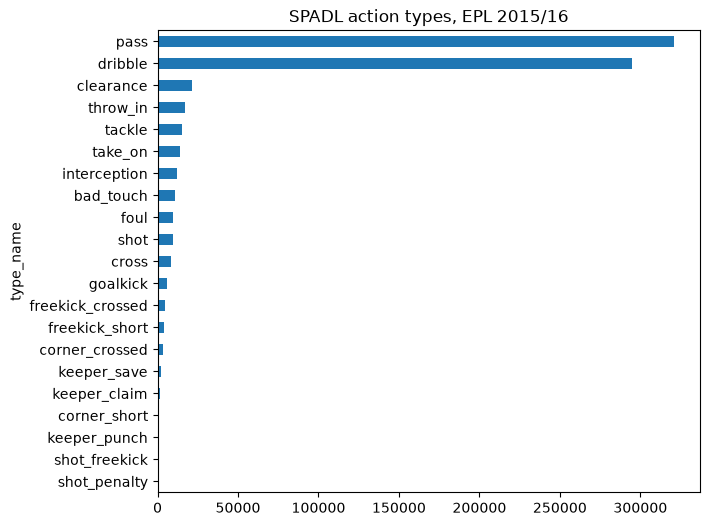

In [10]:
all_actions = pd.concat(actions_by_game.values(), ignore_index=True)
print(len(all_actions), "total actions")
all_actions["type_name"].value_counts().plot(kind="barh", figsize=(7, 6))
plt.title("SPADL action types, EPL 2015/16"); plt.gca().invert_yaxis(); plt.show()

## 3. Game states, features, and labels (3 previous actions, 10-action horizon)

In [11]:
from socceraction.vaep import VAEP
vaep = VAEP(nb_prev_actions=3)   # S_i = {a_{i-2}, a_{i-1}, a_i}

X_parts, y_parts, meta_parts = [], [], []
for _, game in tqdm(games.iterrows(), total=len(games)):
    if game.game_id not in actions_by_game:
        continue
    acts = actions_by_game[game.game_id]
    X_parts.append(vaep.compute_features(game, acts))
    y_parts.append(vaep.compute_labels(game, acts))      # columns: scores, concedes
    meta_parts.append(acts[["game_id", "period_id", "time_seconds", "team_id",
                            "player_id", "type_name", "result_name"]])

X_all = pd.concat(X_parts, ignore_index=True).astype("float32")
y_all = pd.concat(y_parts, ignore_index=True).astype(int)
meta  = pd.concat(meta_parts, ignore_index=True)

print("X:", X_all.shape, "| y:", y_all.shape, "| meta:", meta.shape)
print("positive rate:"); print(y_all.mean())

100%|██████████| 380/380 [01:07<00:00,  5.63it/s]


X: (758434, 568) | y: (758434, 2) | meta: (758434, 7)
positive rate:
scores      0.010907
concedes    0.002112
dtype: float64


## 4. Match-level split (70/15/15)

In [15]:
rng = np.random.default_rng(42)
game_ids = rng.permutation(games.game_id.values)
n = len(game_ids)
train_ids = game_ids[: int(0.70 * n)]
val_ids   = game_ids[int(0.70 * n): int(0.85 * n)]
test_ids  = game_ids[int(0.85 * n):]

def split(ids):
    m = meta.game_id.isin(ids).values
    return X_all[m], y_all[m], meta[m]

X_tr, y_tr, m_tr = split(train_ids)
X_va, y_va, m_va = split(val_ids)
X_te, y_te, m_te = split(test_ids)
print(len(train_ids), len(val_ids), len(test_ids), "games |", len(X_tr), len(X_va), len(X_te), "actions")

266 57 57 games | 533561 113035 111838 actions


## 5. Experiment 1: model comparison (validation set)

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

def make_models():
    return {
        "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "DecisionTree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=42),
        "GradBoost": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1,
                                                    max_depth=5, random_state=42),
    }

def metrics(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p), "LogLoss": log_loss(y, p)}

models, rows = {}, []
for target in ["scores", "concedes"]:
    for name, model in make_models().items():
        model.fit(X_tr, y_tr[target])
        p = model.predict_proba(X_va)[:, 1]
        rows.append({"target": target, "model": name, **metrics(y_va[target], p)})
        models[(target, name)] = model

val_results = pd.DataFrame(rows)
val_results

,target,model,ROC-AUC,Brier,LogLoss
0,scores,LogReg,0.809278,0.009582,0.049518
1,scores,DecisionTree,0.792952,0.009553,0.049949
2,scores,GradBoost,0.805341,0.009569,0.049470
3,concedes,LogReg,0.831607,0.001924,0.011930
4,concedes,DecisionTree,0.785291,0.001923,0.013339
5,concedes,GradBoost,0.788944,0.002082,0.013299


## Precision, Recall, and F1 Score

In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score

classification_rows = []
for (target, name), model in models.items():
    p = model.predict_proba(X_va)[:, 1]
    y_pred = (p >= 0.5).astype(int)

    classification_rows.append({
        "target": target,
        "model": name,
        "Precision": precision_score(y_va[target], y_pred, zero_division=0),
        "Recall": recall_score(y_va[target], y_pred, zero_division=0),
        "F1": f1_score(y_va[target], y_pred, zero_division=0)
    })

results = pd.DataFrame(classification_rows)
results

,target,model,Precision,Recall,F1
0,scores,LogReg,1.000000,0.117601,0.210452
1,scores,DecisionTree,0.956250,0.120758,0.214436
2,scores,GradBoost,0.949686,0.119179,0.211781
3,concedes,LogReg,0.000000,0.000000,0.000000
4,concedes,DecisionTree,0.500000,0.035874,0.066946
5,concedes,GradBoost,0.170213,0.035874,0.059259


## 6. Experiment 2: Feature Analysis

In [24]:
# Group A: Current action type and result
group_A = [
    col for col in X_all.columns
    if col.endswith("_a0")
    and col.startswith(("actiontype_", "result_"))
]

# Spatial features of the current action
spatial_features = [
    col for col in X_all.columns
    if col.endswith("_a0")
    and col.startswith(("start_", "end_", "dx_", "dy_", "movement_"))
]

# Group B: Action + spatial features
group_B = group_A + spatial_features

# Group C: All action, spatial, and contextual features
group_C = X_all.columns.tolist()

feature_groups = {
    "A": group_A,
    "B": group_B,
    "C": group_C
}

for name, features in feature_groups.items():
    print(f"Group {name}: {len(features)} features")

Group A: 167 features
Group B: 178 features
Group C: 568 features


## Model Training and Feature Group Comparison

In [33]:
feature_models = {}
feature_rows = []

for group_name, features in feature_groups.items():
    for target in ["scores", "concedes"]:

        if group_name == "C":
            model = models[(target, "LogReg")]

        else:
            model = make_pipeline(
                StandardScaler(),
                LogisticRegression(max_iter=1000)
            )

            model.fit(X_tr[features], y_tr[target])

        p = model.predict_proba(X_va[features])[:, 1]

        feature_rows.append({
            "group": group_name,
            "target": target,
            "num_features": len(features),
            **metrics(y_va[target], p)
        })

        feature_models[(group_name, target)] = model

feature_results = pd.DataFrame(feature_rows)
feature_results

,group,target,num_features,ROC-AUC,Brier,LogLoss
0,A,scores,167,0.666193,0.009741,0.053822
1,A,concedes,167,0.799009,0.001940,0.012372
2,B,scores,178,0.806709,0.009588,0.049654
3,B,concedes,178,0.831655,0.001924,0.011938
4,C,scores,568,0.809278,0.009582,0.049518
5,C,concedes,568,0.831607,0.001924,0.011930


## Feature Group Performance

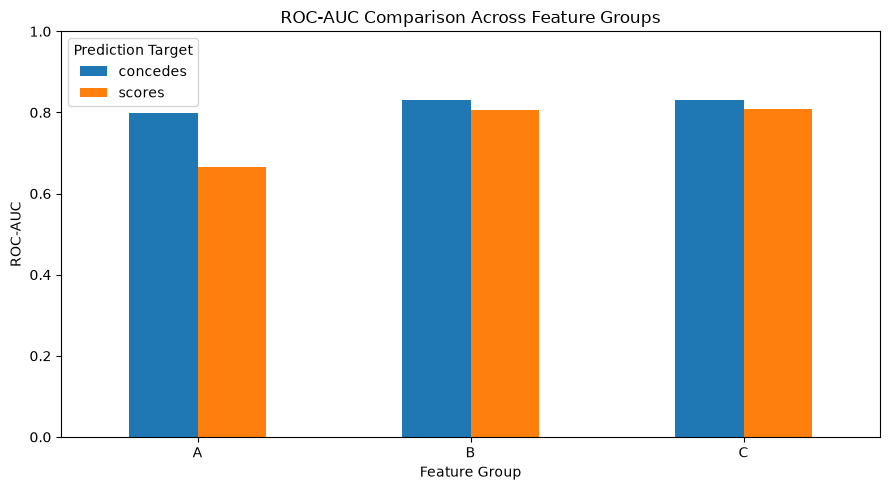

In [26]:
feature_auc = feature_results.pivot(
    index="group",
    columns="target",
    values="ROC-AUC"
)

feature_auc.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("ROC-AUC Comparison Across Feature Groups")
plt.xlabel("Feature Group")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.legend(title="Prediction Target")
plt.tight_layout()
plt.show()

## Permutation Importance Analysis

In [30]:
from sklearn.inspection import permutation_importance

X_sample = X_va.sample(n=20000, random_state=42)
y_sample = y_va.loc[X_sample.index]

importance_results = {}

for target in ["scores", "concedes"]:
    model = feature_models[("C", target)]

    result = permutation_importance(
        model,
        X_sample,
        y_sample[target],
        scoring="roc_auc",
        n_repeats=3,
        random_state=42,
        n_jobs=1
    )

    importance_results[target] = pd.DataFrame({
        "feature": X_sample.columns,
        "importance": result.importances_mean,
        "std": result.importances_std
    }).sort_values("importance", ascending=False)

print("Top 10 features for scoring prediction:")
display(importance_results["scores"].head(10))

print("Top 10 features for conceding prediction:")
display(importance_results["concedes"].head(10))

Calculating feature importance for scores
Calculating feature importance for concedes
Top 10 features for scoring prediction:


,feature,importance,std
540,end_dist_to_goal_a0,0.051345,0.004526
546,dx_a0,0.019781,0.009142
528,end_x_a0,0.010687,0.002595
541,end_angle_to_goal_a0,0.009219,0.003448
534,start_dist_to_goal_a0,0.004512,0.000812
542,end_dist_to_goal_a1,0.004161,0.000796
549,dx_a1,0.003878,0.001270
70,result_success_a0,0.003496,0.004165
69,result_fail_a0,0.002939,0.003832
87,actiontype_pass_result_fail_a0,0.002640,0.001754


Top 10 features for conceding prediction:


,feature,importance,std
88,actiontype_pass_result_success_a0,0.012392,0.004125
546,dx_a0,0.008456,0.002816
196,actiontype_clearance_result_success_a0,0.007566,0.004419
18,actiontype_clearance_a0,0.007566,0.004419
548,movement_a0,0.006508,0.002058
0,actiontype_pass_a0,0.005578,0.002318
237,actiontype_throw_in_result_fail_a1,0.003941,0.000021
10,actiontype_interception_a0,0.003044,0.000026
58,actiontype_shot_penalty_a2,0.003015,0.004278
436,actiontype_shot_penalty_result_success_a2,0.002704,0.003837
